In [1]:
# Setup
import json

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

DATA_FILE = "TEP_Run_Full_raw.h5"
T_RANGE = None

In [2]:
# Load data
FAULT_TYPES = {**{i: "step" for i in range(1, 8)}, **{i: "random walk" for i in range(8, 15)},
               15: "pulse", 16: "pulse", 17: "pulse", 18: "stiction", 19: "stiction", 20: "stiction"}
FAULT_NAMES = {
    1: "A/C feed ratio, B composition constant", 2: "B composition, A/C ratio constant",
    3: "D feed temperature", 4: "Reactor CW inlet temperature", 5: "Condenser CW inlet temperature",
    6: "A feed loss", 7: "C header pressure loss", 8: "A, B, C feed composition", 9: "D feed temperature",
    10: "C feed temperature", 11: "Reactor CW inlet temperature", 12: "Condenser CW inlet temperature",
    13: "Reaction kinetics", 14: "Stripper steam heat transfer", 15: "Reactor heat transfer",
    16: "Condenser heat transfer", 17: "Reactor-separator flow", 18: "Reactor CW valve",
    19: "Condenser CW valve", 20: "Recycle, separator, stripper product and steam valves",
}


def read_names(ds):
    return [n.decode() if isinstance(n, bytes) else str(n) for n in ds.attrs["names"]]


data, names = {}, {}
with h5py.File(DATA_FILE, "r") as f:
    t = f["t"][()] / 3600
    for key in ["xmeas", "xmv", "sp", "dist", "y"]:
        if key in f:
            data[key] = f[key][()]
            names[key] = read_names(f[key])
    idv = f["idv_effective"][()]
    shutdown = bool(f.attrs.get("shutdown", False))
    config = json.loads(f.attrs["config"]) if "config" in f.attrs else {}

fault = np.where(idv.any(axis=1), idv.argmax(axis=1) + 1, 0)

if T_RANGE is None:
    shown = np.ones(len(t), dtype=bool)
else:
    shown = (t >= T_RANGE[0]) & (t <= T_RANGE[1])

print(f"{DATA_FILE}: {len(t)} samples, {t[0]:.2f} - {t[-1]:.2f} h, every {(t[1] - t[0]) * 60:.0f} min"
      + (", plant shut down" if shutdown else ""))
print(f"noise: {config.get('noise')}, seed: {config.get('seed')}")
print("datasets: " + ", ".join(f"{k} {v.shape}" for k, v in data.items()))

TEP_Run_Full_raw.h5: 7000 samples, 0.05 - 350.00 h, every 3 min
noise: True, seed: 0
datasets: xmeas (7000, 41), xmv (7000, 12), sp (7000, 20), dist (7000, 12), y (7000, 50)


In [3]:
# Fault events
events = []   # (start index, end index, fault number)
for k in range(idv.shape[1]):
    on = idv[:, k] == 1
    for i in range(len(on)):
        if on[i] and (i == 0 or not on[i - 1]):
            start = i
        if on[i] and (i == len(on) - 1 or not on[i + 1]):
            events.append((start, i, k + 1))
events.sort()

event_table = pd.DataFrame(
    [
        {
            "IDV": f,
            "type": FAULT_TYPES[f],
            "description": FAULT_NAMES[f],
            "start sample": s,
            "end sample": e,
            "start (h)": round(t[s], 2),
            "end (h)": round(t[e], 2),
            "duration (h)": round(t[e] - t[s] + t[1] - t[0], 2),
        }
        for s, e, f in events
    ]
)
event_table.index.name = "EVENT_INDEX"
print(f"{len(events)} fault events, {(fault == 0).mean():.0%} of samples normal operation, "
      f"{(idv.sum(axis=1) > 1).sum()} samples with overlapping faults")
print("EVENT_INDEX matches the forecast notebooks only when DATA_FILE is the file they load (TEP_Run_Full_raw.h5)")
pd.set_option("display.max_rows", 200)
event_table

44 fault events, 53% of samples normal operation, 0 samples with overlapping faults
EVENT_INDEX matches the forecast notebooks only when DATA_FILE is the file they load (TEP_Run_Full_raw.h5)


,IDV,type,description,start sample,end sample,start (h),end (h),duration (h)
EVENT_INDEX,,,,,,,,
0,1,step,"A/C feed ratio, B composition constant",199,278,10.00,13.95,4.00
1,8,random walk,"A, B, C feed composition",373,494,18.70,24.75,6.10
2,15,pulse,Reactor heat transfer,578,649,28.95,32.50,3.60
3,4,step,Reactor CW inlet temperature,709,788,35.50,39.45,4.00
4,11,random walk,Reactor CW inlet temperature,881,969,44.10,48.50,4.45
5,18,stiction,Reactor CW valve,1049,1128,52.50,56.45,4.00
6,2,step,"B composition, A/C ratio constant",1219,1298,61.00,64.95,4.00
7,12,random walk,Condenser CW inlet temperature,1391,1472,69.60,73.65,4.10
8,16,pulse,Condenser heat transfer,1578,1677,78.95,83.90,5.00


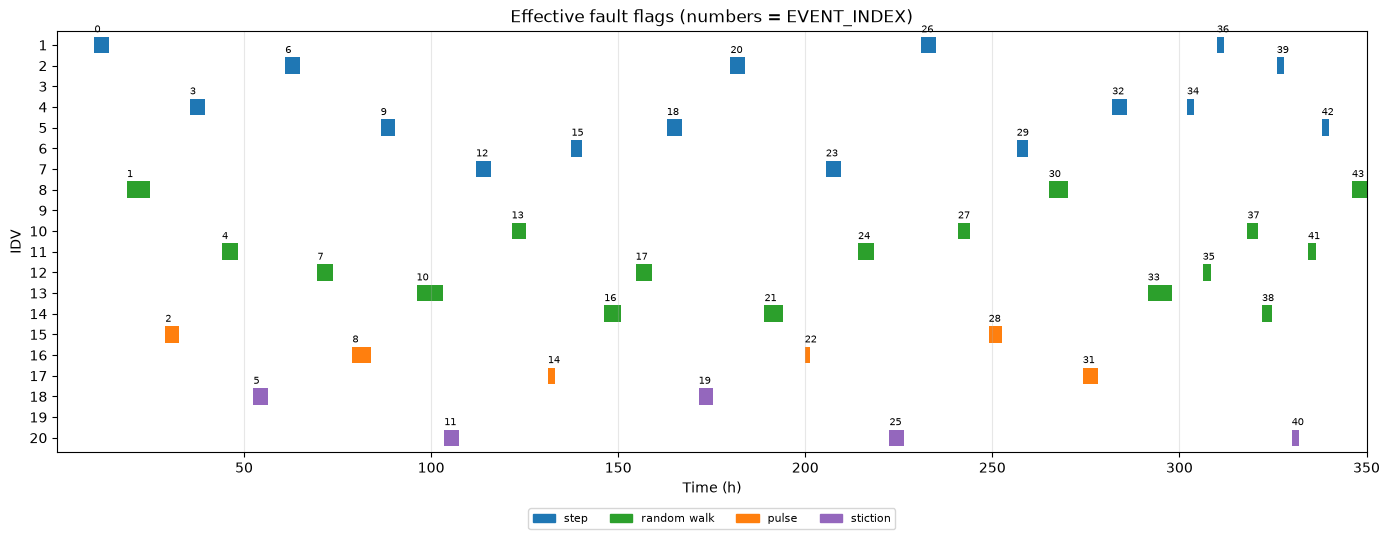

In [4]:
# Fault flags
COLORS = {"step": "tab:blue", "random walk": "tab:green", "pulse": "tab:orange", "stiction": "tab:purple"}

fig, ax = plt.subplots(figsize=(14, 5.5))
for f in range(1, 21):
    ax.fill_between(t[shown], f - 0.4, f + 0.4, where=idv[shown, f - 1] == 1, step="post",
                    color=COLORS[FAULT_TYPES[f]], lw=0)
for k, (s, e, f) in enumerate(events):
    if shown[s]:
        ax.text(t[s], f - 0.5, str(k), fontsize=7, ha="left", va="bottom")
for kind, color in COLORS.items():
    ax.fill_between([], [], color=color, label=kind)
ax.set_yticks(range(1, 21))
ax.set_ylim(0.3, 20.7)
ax.invert_yaxis()
ax.set_xlim(t[shown][0], t[shown][-1])
ax.set_ylabel("IDV")
ax.set_xlabel("Time (h)")
ax.set_title("Effective fault flags (numbers = EVENT_INDEX)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8, ncols=4)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

In [5]:
# Plotting
fault_on = fault[shown] != 0


def grid(values, labels, title, ncols):
    n = values.shape[1]
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.2 * nrows), sharex=True)
    for i, ax in enumerate(axes.ravel()):
        if i >= n:
            ax.axis("off")
            continue
        ax.fill_between(t[shown], 0, 1, where=fault_on, color="tab:red", alpha=0.1,
                        transform=ax.get_xaxis_transform(), step="post", lw=0)
        ax.plot(t[shown], values[shown, i], lw=0.6)
        ax.set_title(f"{i + 1}. {labels[i]}", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Time (h)", fontsize=8)
    fig.suptitle(f"{title} - {DATA_FILE} (red: fault acting)")
    fig.tight_layout()
    plt.show()

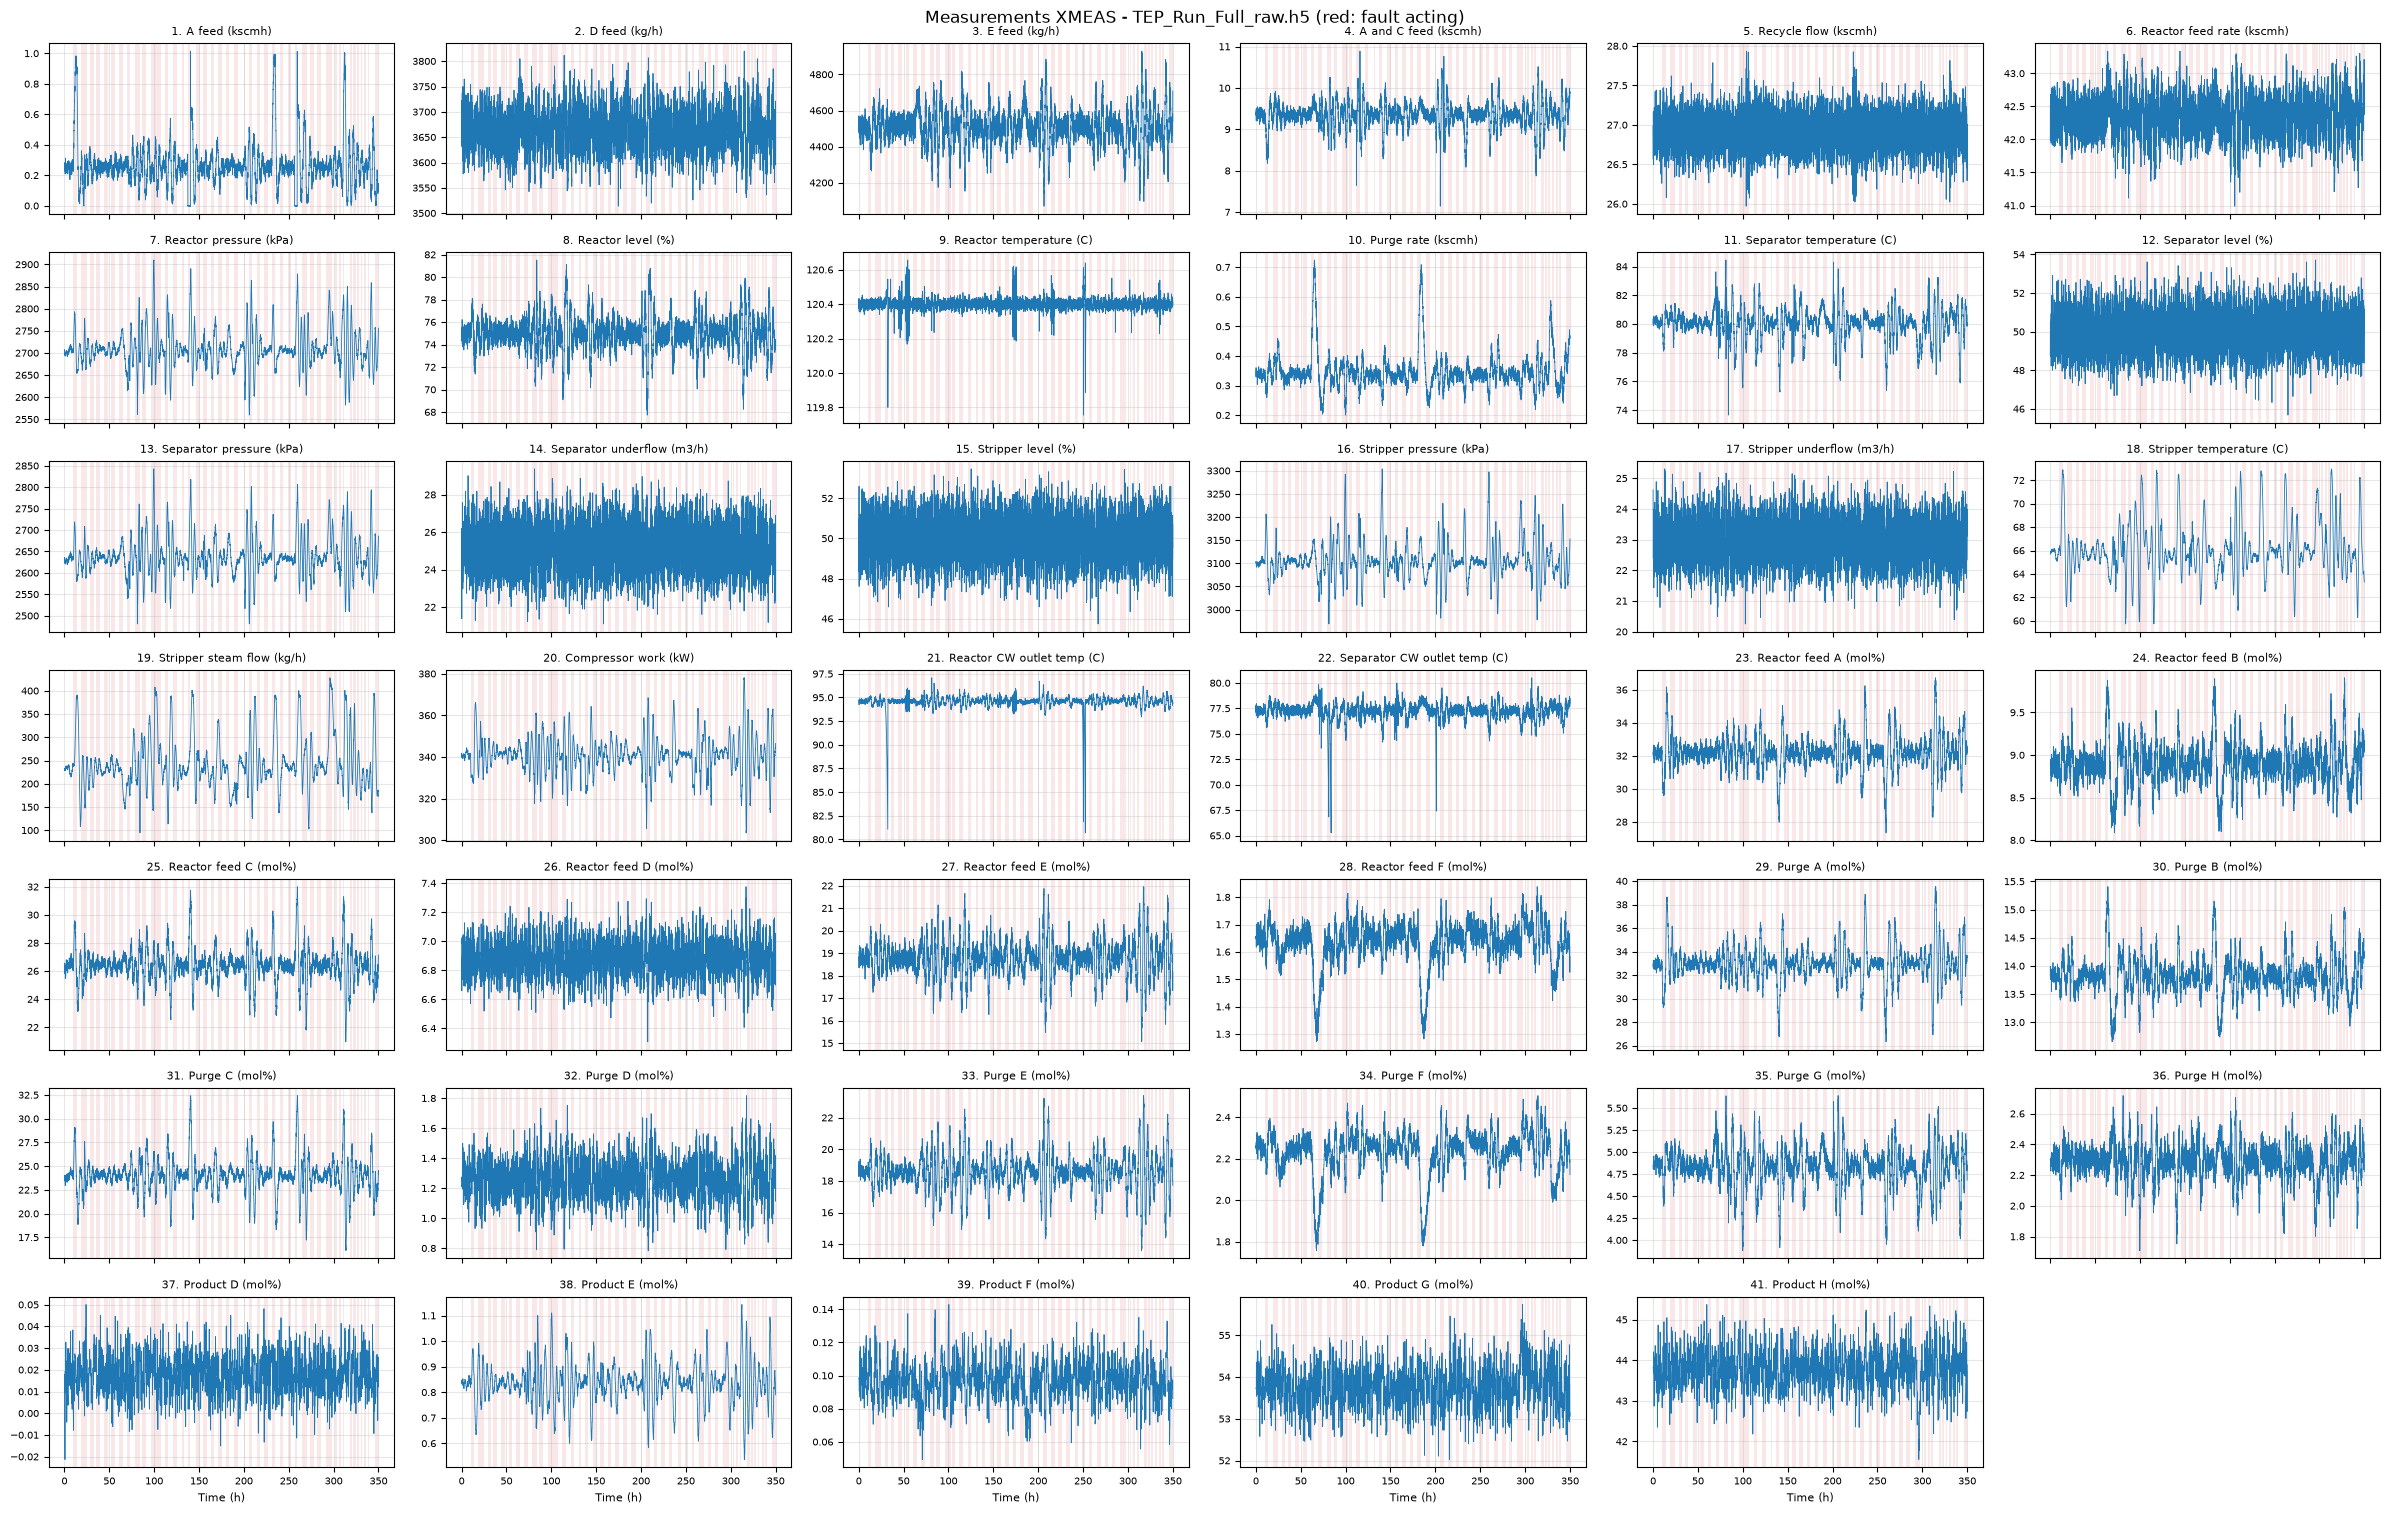

In [6]:
# Measurements XMEAS
grid(data["xmeas"], names["xmeas"], "Measurements XMEAS", 6)

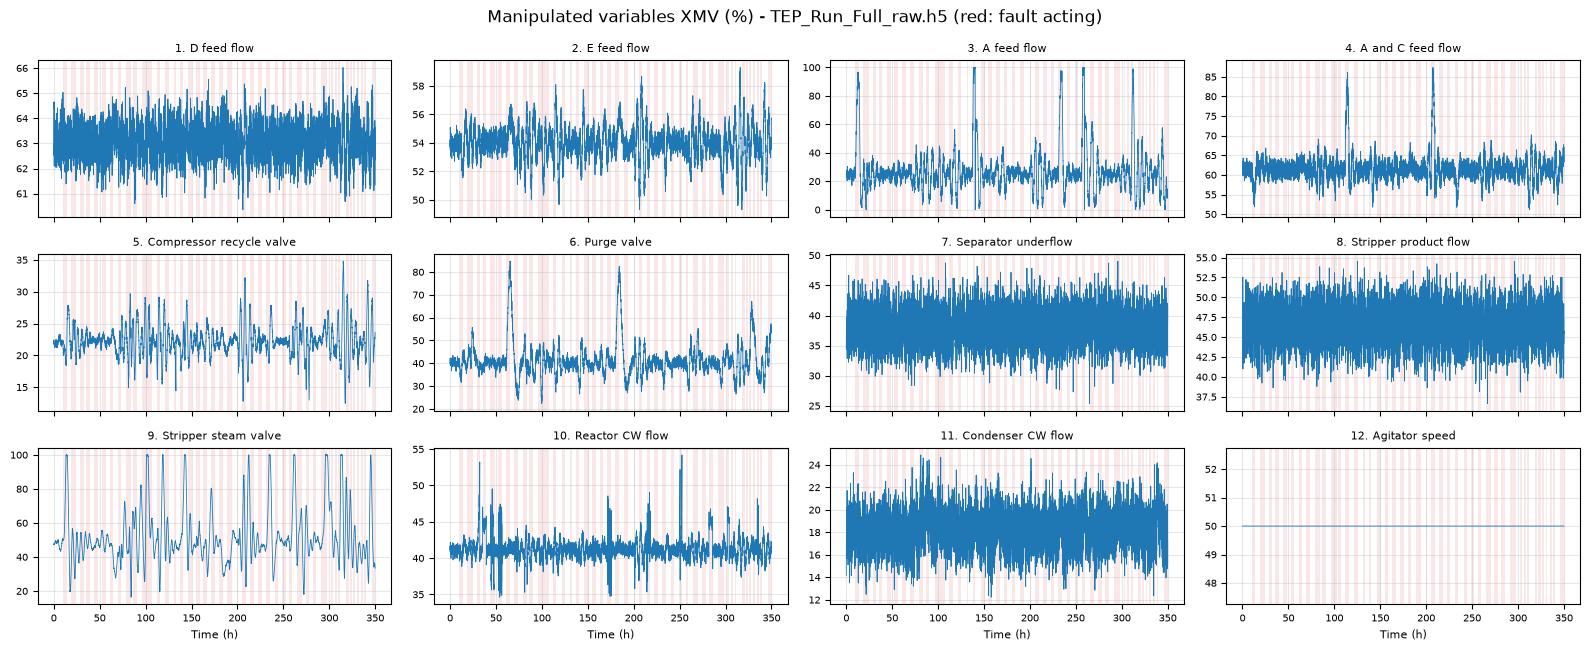

In [7]:
# Manipulated variables XMV (valve commands)
grid(data["xmv"], names["xmv"], "Manipulated variables XMV (%)", 4)

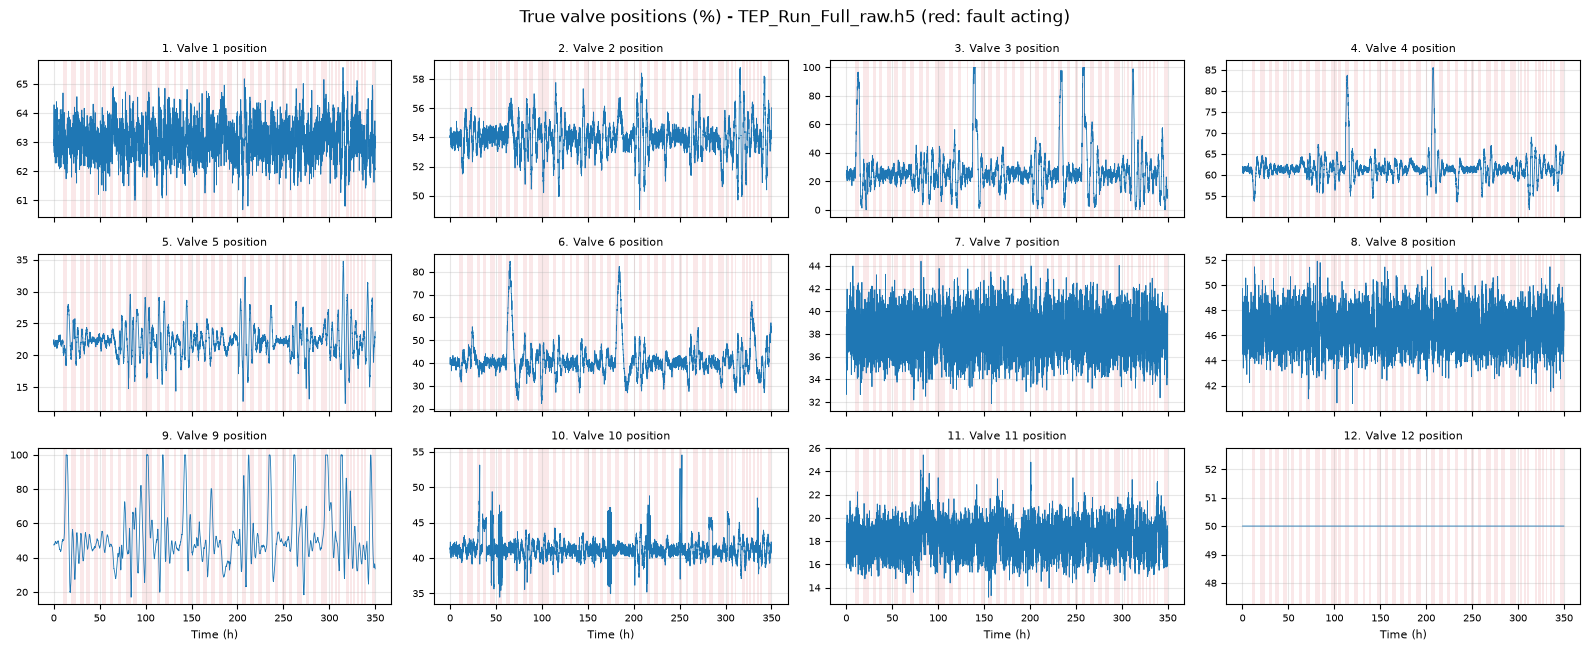

In [8]:
# True valve positions
if "y" in data:
    grid(data["y"][:, 38:50], names["y"][38:50], "True valve positions (%)", 4)

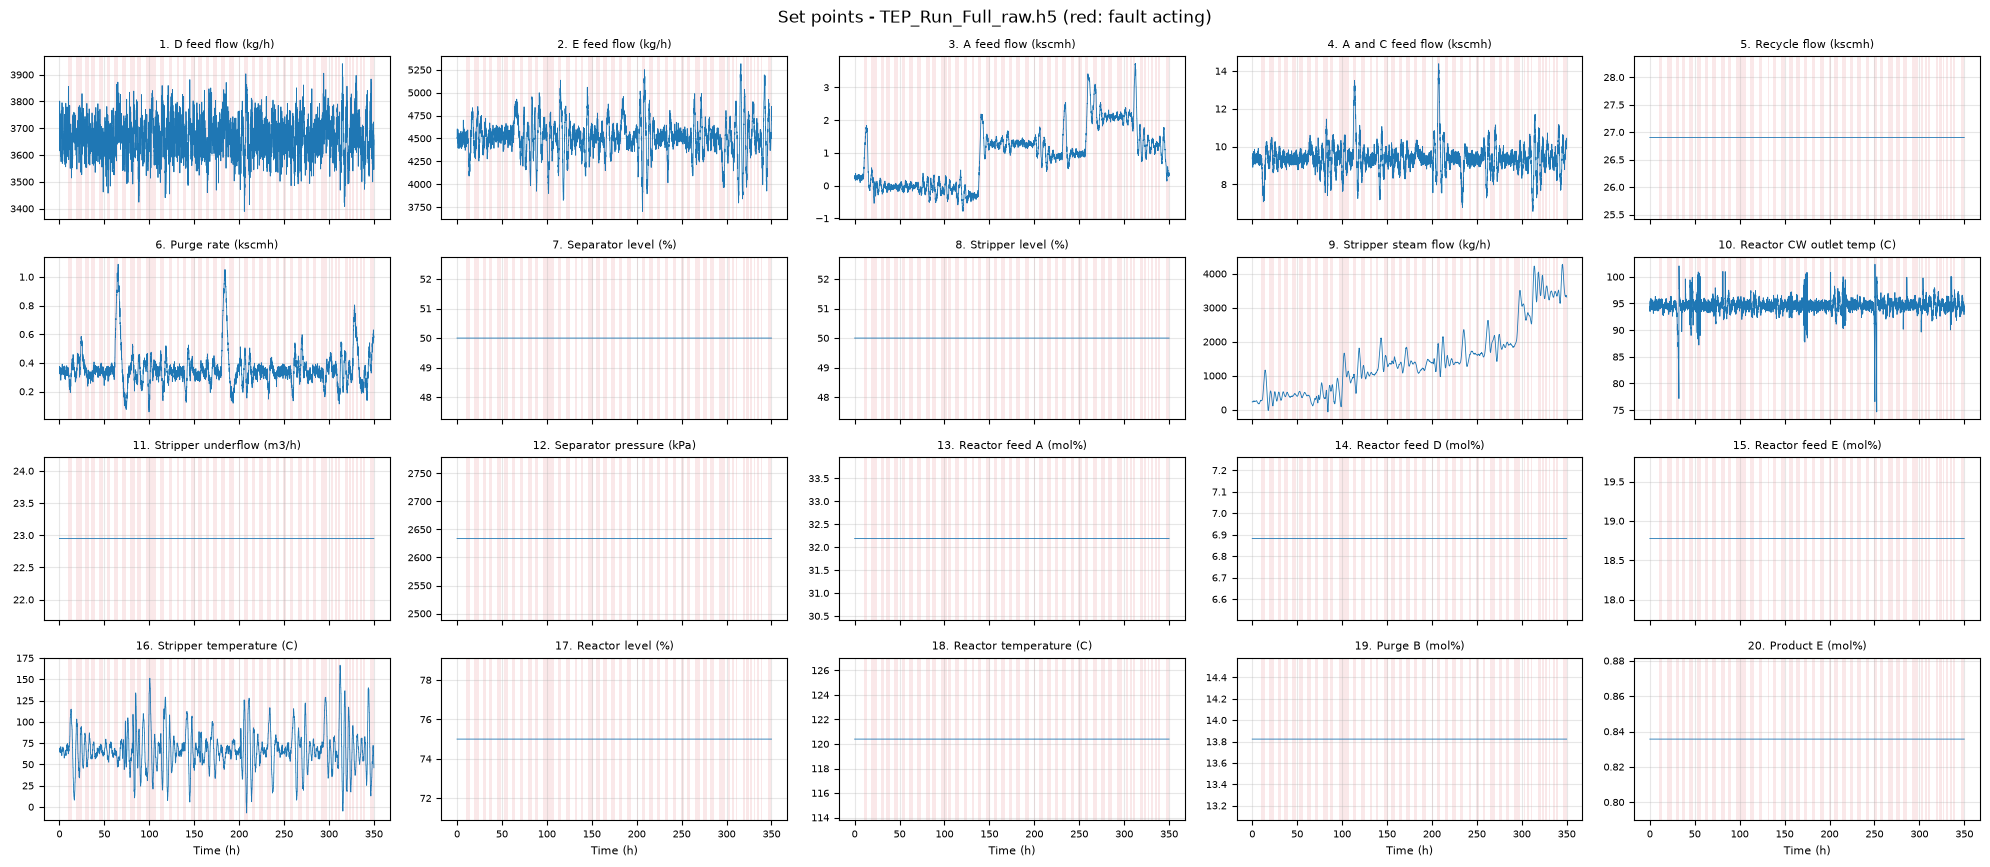

In [9]:
# Set points
grid(data["sp"], names["sp"], "Set points", 5)

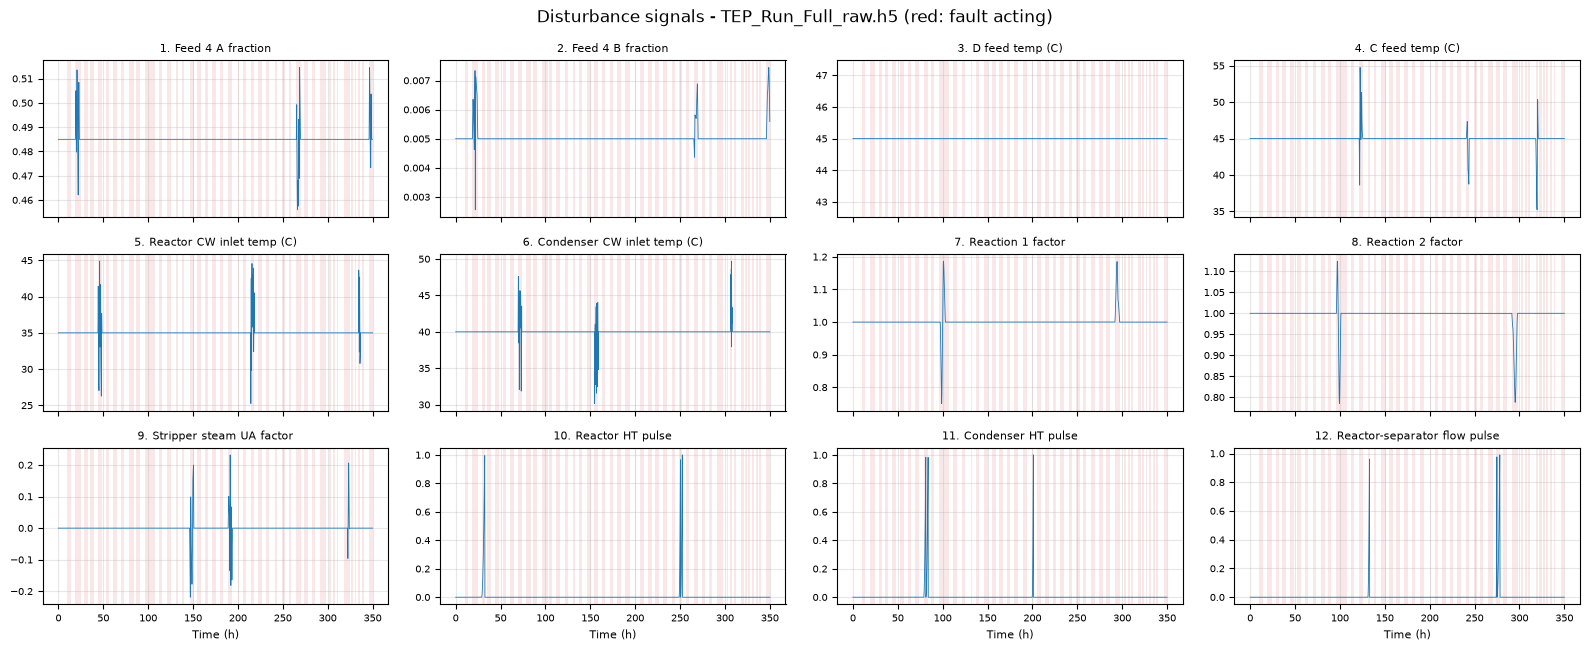

In [10]:
# Disturbance signals
grid(data["dist"], names["dist"], "Disturbance signals", 4)

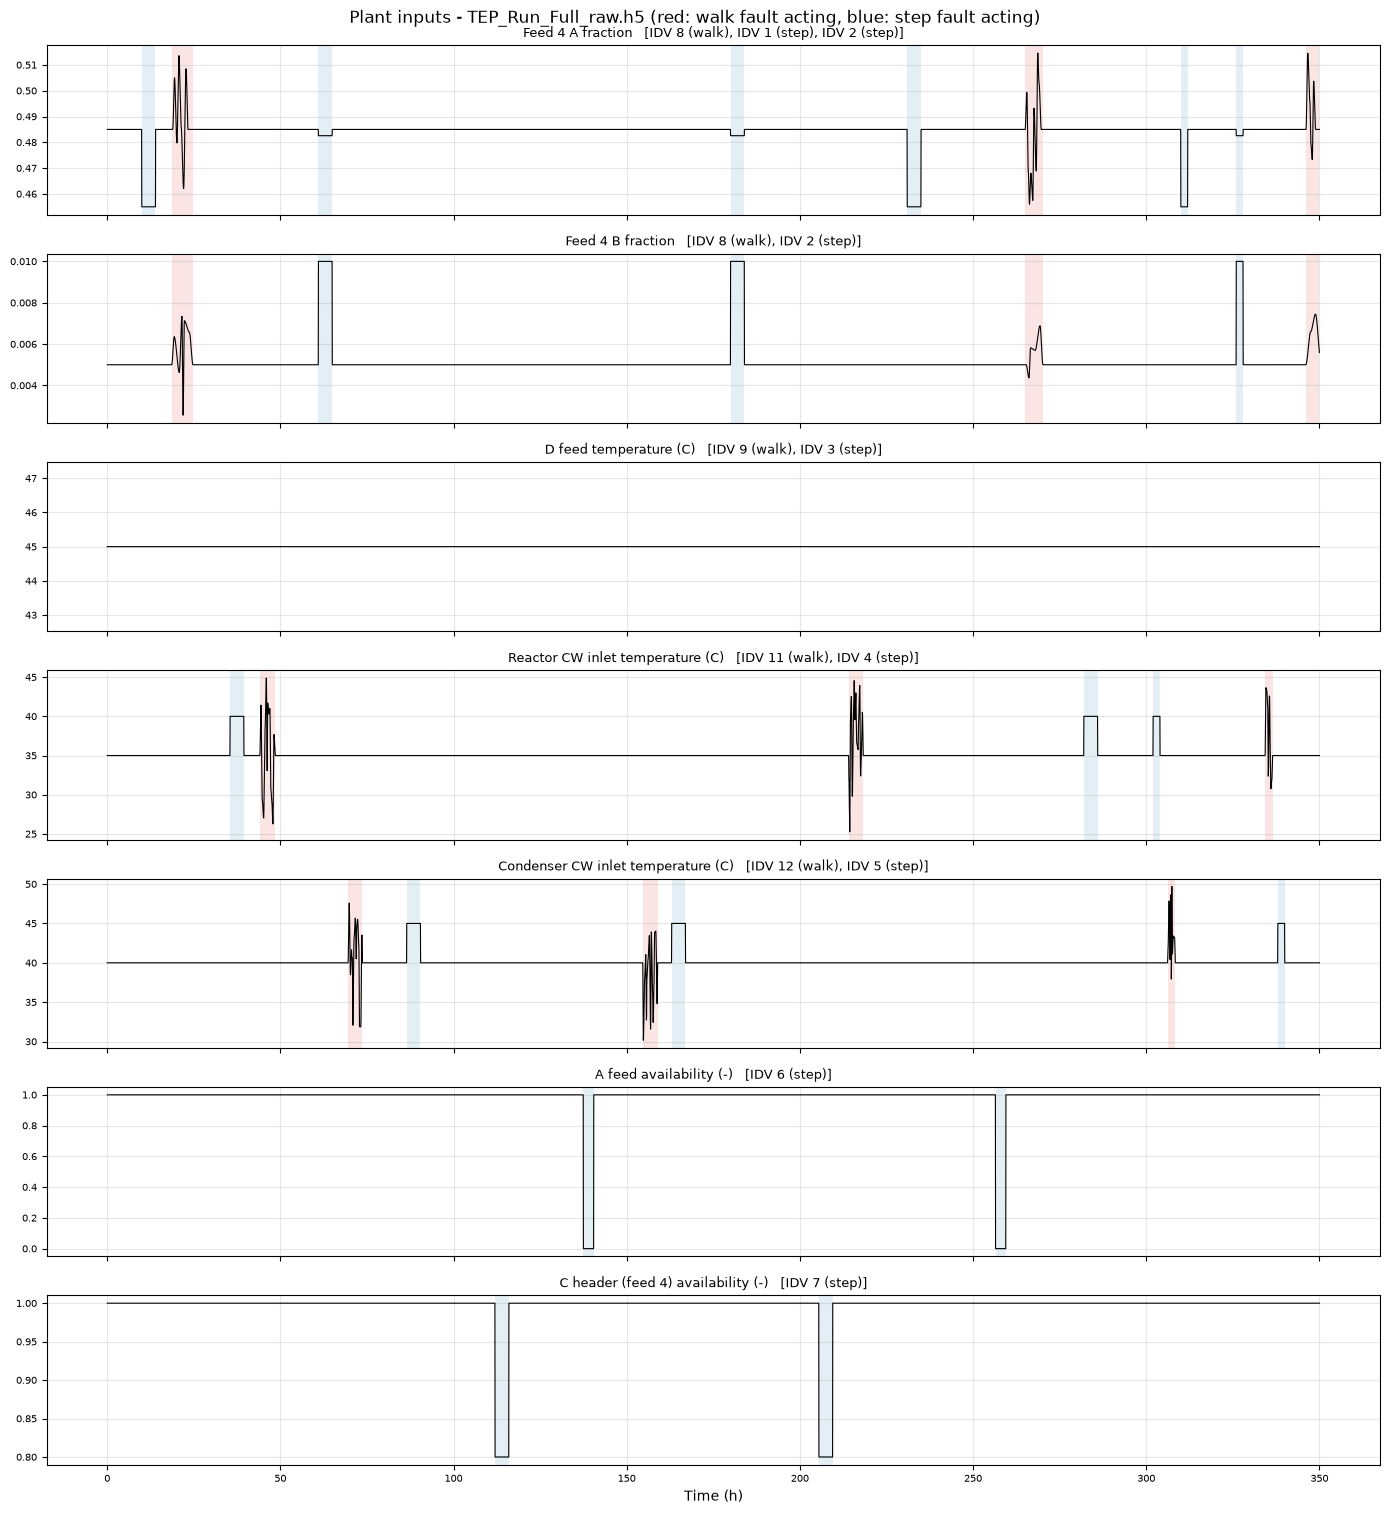

In [11]:
# Plant inputs
def on(f):
    return idv[:, f - 1]


dist = data["dist"]
inputs = {
    "Feed 4 A fraction": (dist[:, 0] - on(1) * 0.03 - on(2) * 2.43719e-3, [8], [1, 2]),
    "Feed 4 B fraction": (dist[:, 1] + on(2) * 0.005, [8], [2]),
    "D feed temperature (C)": (dist[:, 2] + on(3) * 5.0, [9], [3]),
    "Reactor CW inlet temperature (C)": (dist[:, 4] + on(4) * 5.0, [11], [4]),
    "Condenser CW inlet temperature (C)": (dist[:, 5] + on(5) * 5.0, [12], [5]),
    "A feed availability (-)": (1.0 - on(6), [], [6]),
    "C header (feed 4) availability (-)": (1.0 - 0.2 * on(7), [], [7]),
}

fig, axes = plt.subplots(len(inputs), 1, figsize=(14, 2.2 * len(inputs)), sharex=True)
for ax, (name, (values, walk_f, step_f)) in zip(axes, inputs.items()):
    for f in walk_f:
        ax.fill_between(t[shown], 0, 1, where=on(f)[shown] == 1, color="tab:red", alpha=0.12,
                        transform=ax.get_xaxis_transform(), step="post", lw=0)
    for f in step_f:
        ax.fill_between(t[shown], 0, 1, where=on(f)[shown] == 1, color="tab:blue", alpha=0.12,
                        transform=ax.get_xaxis_transform(), step="post", lw=0)
    ax.plot(t[shown], values[shown], lw=0.8, color="k")
    tags = ", ".join([f"IDV {f} (walk)" for f in walk_f] + [f"IDV {f} (step)" for f in step_f])
    ax.set_title(f"{name}   [{tags}]", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (h)")
fig.suptitle(f"Plant inputs - {DATA_FILE} (red: walk fault acting, blue: step fault acting)")
fig.tight_layout()
plt.show()

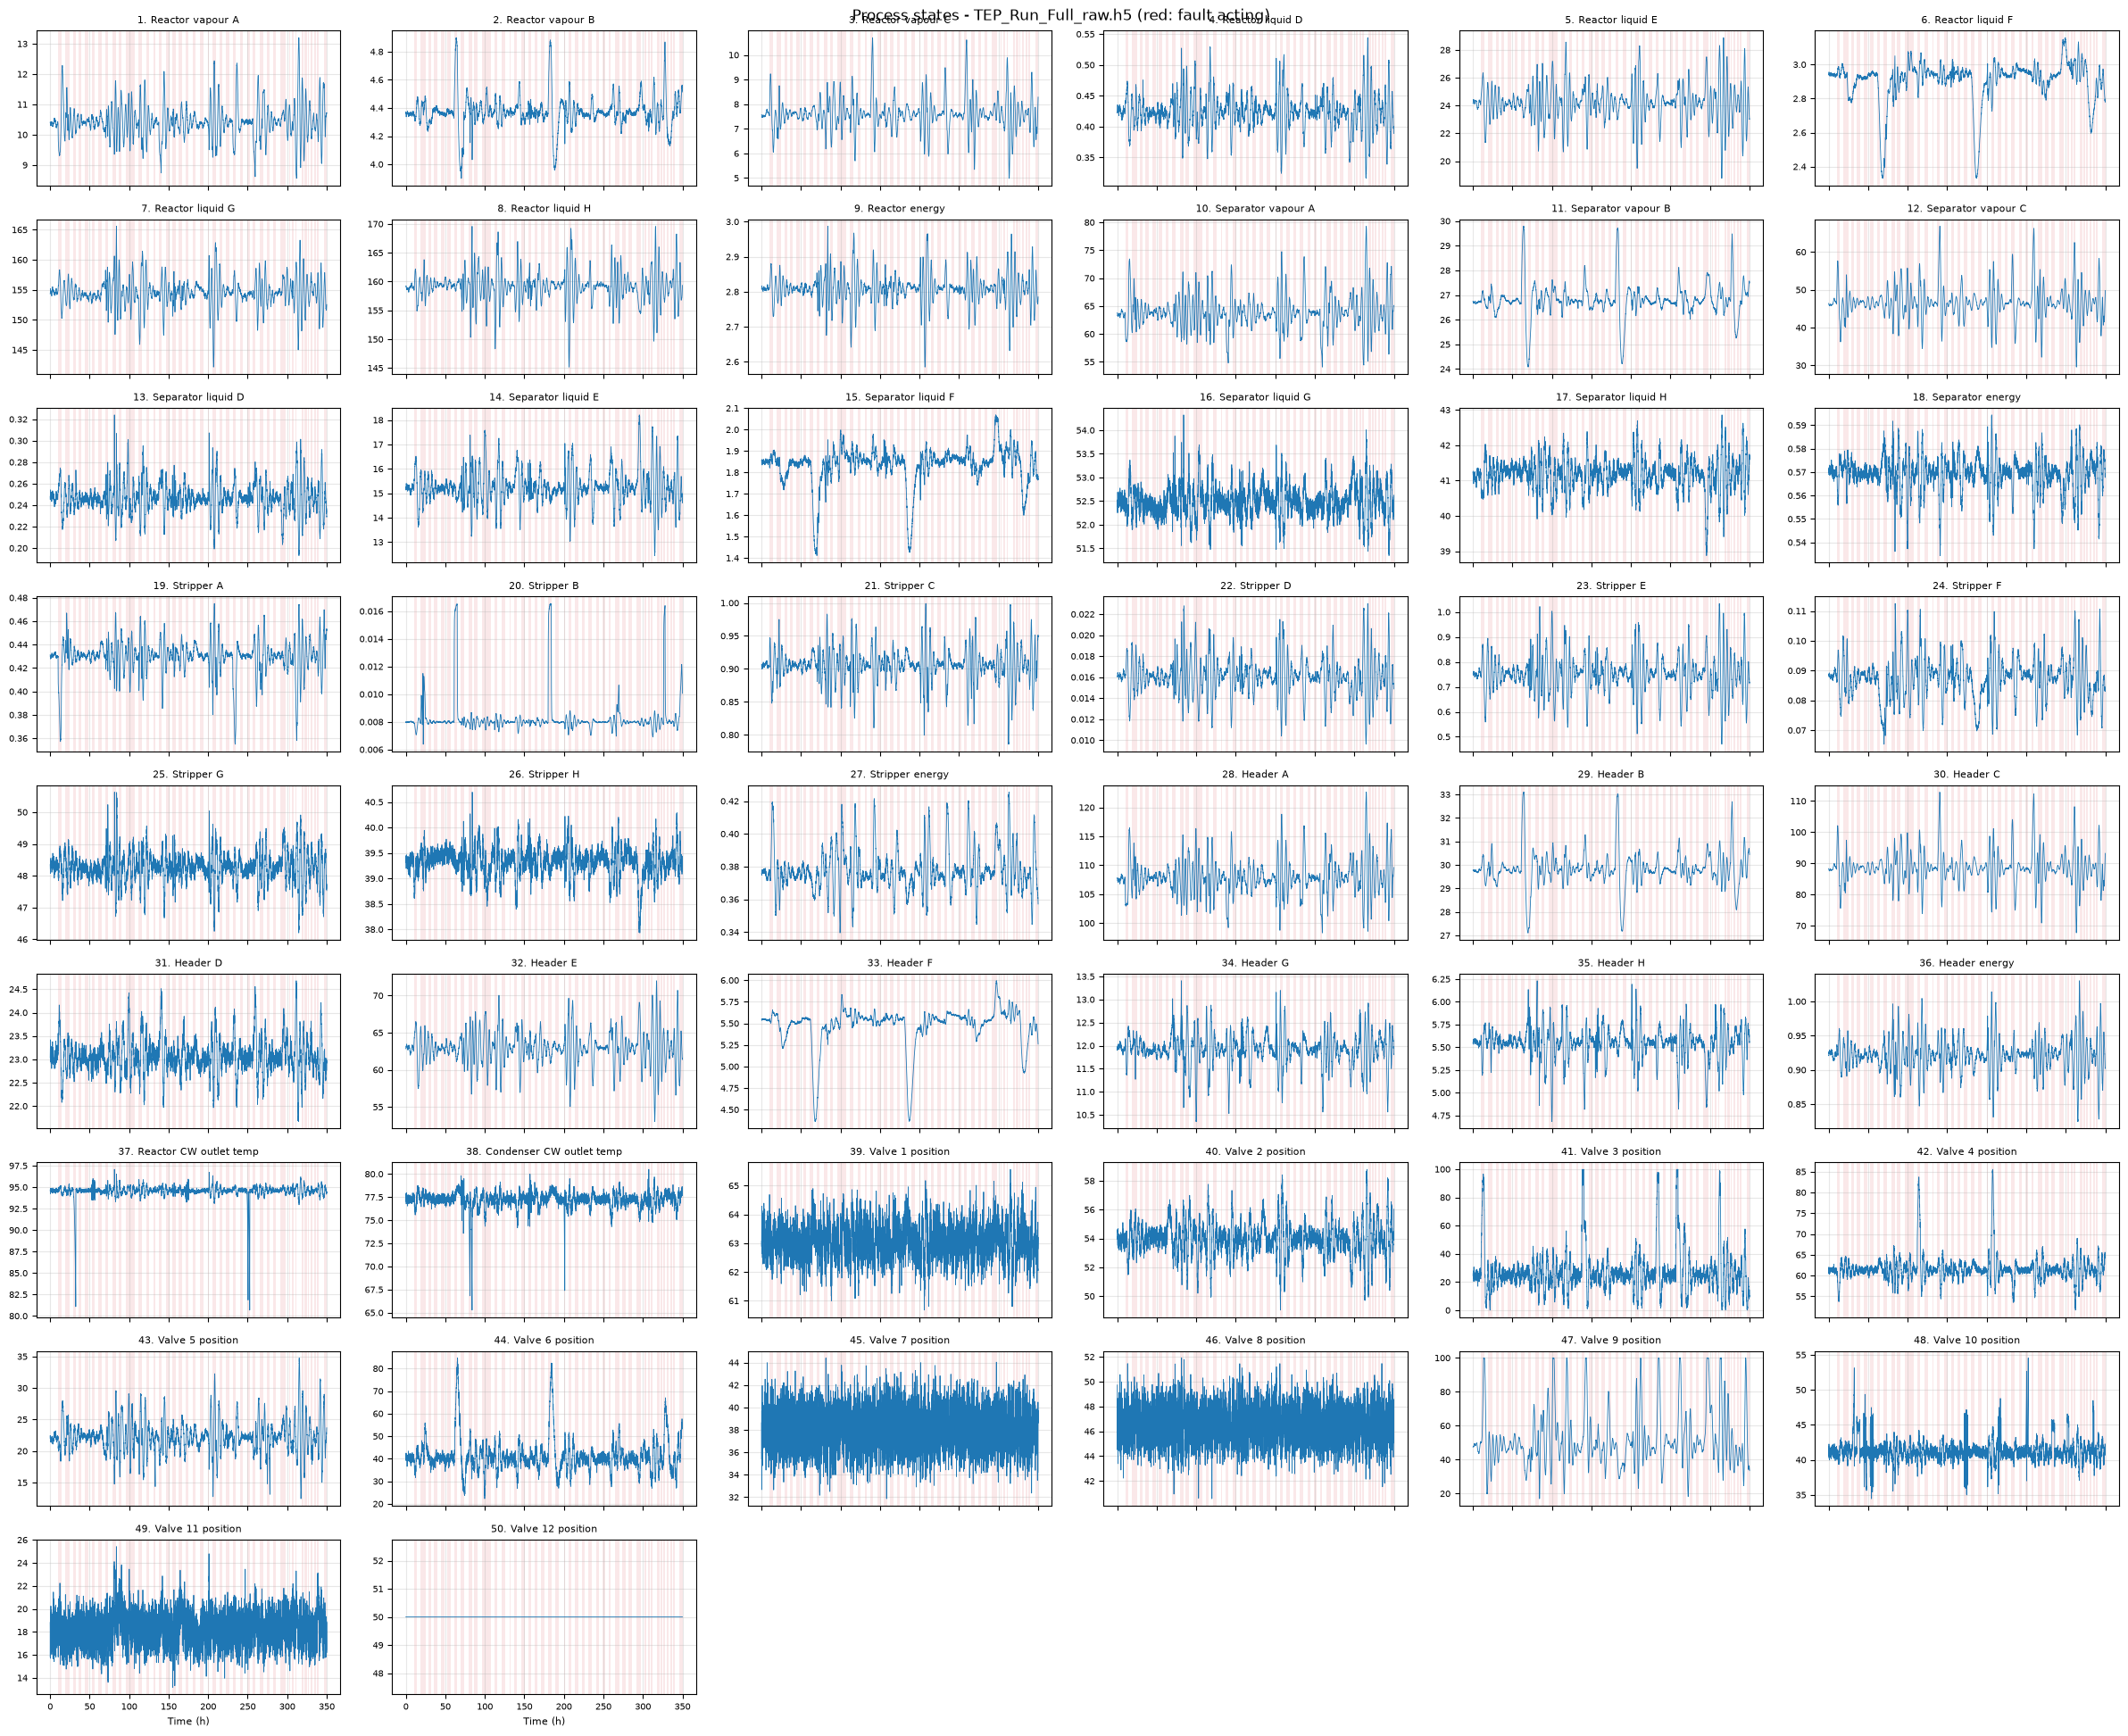

In [12]:
# Process states
if "y" in data:
    grid(data["y"], names["y"], "Process states", 6)